In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import joblib

from sklearn.ensemble import IsolationForest
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

np.random.seed(42)
torch.manual_seed(42)

print("AetherHound ML Environment Ready!")
print("PyTorch:", torch.__version__)


AetherHound ML Environment Ready!
PyTorch: 2.14.1+cpu


In [ ]:

rng = np.random.default_rng(42)

features = [
    "signal_power",
    "spectral_entropy",
    "peak_frequency",
    "bandwidth",
    "noise_level"
]

normal = np.column_stack([
    rng.normal(0.5, 0.08, 1000),
    rng.normal(0.7, 0.05, 1000),
    rng.normal(1000, 100, 1000),
    rng.normal(200, 30, 1000),
    rng.normal(0.1, 0.02, 1000)
])

anomaly = np.column_stack([
    rng.normal(0.9, 0.08, 200),
    rng.normal(0.3, 0.07, 200),
    rng.normal(1800, 150, 200),
    rng.normal(500, 60, 200),
    rng.normal(0.4, 0.05, 200)
])

X = np.vstack([normal, anomaly])
y = np.concatenate([
    np.zeros(1000, dtype=int),
    np.ones(200, dtype=int)
])

df = pd.DataFrame(X, columns=features)
df["label"] = y

df.to_csv("synthetic_signals.csv", index=False)

print("Dataset created:", df.shape)
display(df.head())


Dataset created: (1200, 6)


,signal_power,spectral_entropy,peak_frequency,bandwidth,noise_level,label
0,0.524377,0.697036,954.804902,237.470681,0.105064,0
1,0.416801,0.663536,933.412229,220.630766,0.117904,0
2,0.560036,0.679276,1043.400982,258.983824,0.105466,0
3,0.575245,0.731696,1025.185442,153.565015,0.144777,0
4,0.343917,0.700150,859.520845,192.039197,0.128596,0


In [ ]:

X = df[features]
y = df["label"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5,
    random_state=42, stratify=y_temp
)

X_train_normal = X_train[y_train == 0]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_normal)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Normal training samples:", len(X_train_scaled))
print("Validation samples:", len(X_val_scaled))
print("Testing samples:", len(X_test_scaled))


Normal training samples: 600
Validation samples: 240
Testing samples: 240


In [ ]:

baseline = IsolationForest(
    n_estimators=100,
    contamination=0.05,
    random_state=42
)

baseline.fit(X_train_scaled)

baseline_predictions = (
    baseline.predict(X_test_scaled) == -1
).astype(int)

print("Baseline Model Evaluation")
print(classification_report(
    y_test,
    baseline_predictions,
    target_names=["Normal", "Anomaly"],
    zero_division=0
))


Baseline Model Evaluation
              precision    recall  f1-score   support

      Normal       1.00      0.94      0.97       200
     Anomaly       0.77      1.00      0.87        40

    accuracy                           0.95       240
   macro avg       0.88      0.97      0.92       240
weighted avg       0.96      0.95      0.95       240



In [ ]:

class Autoencoder(nn.Module):
    def __init__(self, input_dim):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Linear(8, 3)
        )

        self.decoder = nn.Sequential(
            nn.Linear(3, 8),
            nn.ReLU(),
            nn.Linear(8, 16),
            nn.ReLU(),
            nn.Linear(16, input_dim)
        )

    def forward(self, x):
        encoded = self.encoder(x)
        reconstructed = self.decoder(encoded)
        return reconstructed


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = Autoencoder(input_dim=len(features)).to(device)

print(model)
print("Device:", device)


Autoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=5, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=3, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=3, out_features=8, bias=True)
    (1): ReLU()
    (2): Linear(in_features=8, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=5, bias=True)
  )
)
Device: cpu


In [ ]:

train_tensor = torch.tensor(
    X_train_scaled, dtype=torch.float32
).to(device)

optimizer = torch.optim.Adam(
    model.parameters(), lr=0.001
)

criterion = nn.MSELoss()

loss_history = []

for epoch in range(100):
    model.train()

    optimizer.zero_grad()

    reconstructed = model(train_tensor)
    loss = criterion(reconstructed, train_tensor)

    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch+1}/100 | "
            f"Loss: {loss.item():.6f}"
        )

print("Autoencoder training completed!")


Epoch 10/100 | Loss: 1.038213
Epoch 20/100 | Loss: 1.026802
Epoch 30/100 | Loss: 1.016780
Epoch 40/100 | Loss: 1.007054
Epoch 50/100 | Loss: 0.996600
Epoch 60/100 | Loss: 0.983788
Epoch 70/100 | Loss: 0.966340
Epoch 80/100 | Loss: 0.942913
Epoch 90/100 | Loss: 0.913234
Epoch 100/100 | Loss: 0.880297
Autoencoder training completed!


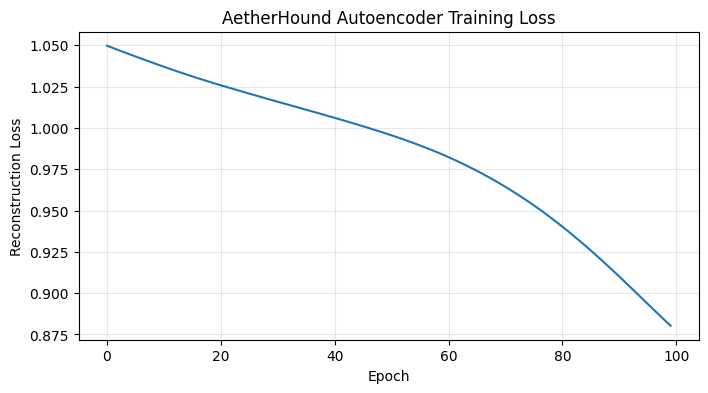

In [ ]:

plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Reconstruction Loss")
plt.title("AetherHound Autoencoder Training Loss")
plt.grid(alpha=0.3)
plt.show()
